# Movie Ratings and Genre Trends

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/drive/12BqXfVyb0z7fRTk13lmIBgGxwu7fU9jD?usp=sharing)

**Project ID:** DA-012 | **Domain:** Entertainment & Media Analytics

**Team Leader:** Khushi Dhami (BCCC2026010)

This project analyzes 1,500 movies to understand viewer ratings, commercial box office earnings, and evolving genre trends over time. We explore the contrast between high-grossing commercial blockbusters and critically acclaimed cinematic dramas, along with the direct impact of film duration on audience reception.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set plot style
sns.set_theme(style="whitegrid")

## Loading the Dataset

We load the movie catalog from `data.csv` using Pandas.

In [2]:
movies = pd.read_csv('data.csv')
movies.head()

,Movie_ID,Title,Release_Year,Genre,Runtime_Minutes,Rating,Votes,Budget_Million,Box_Office_Million
0,MV-10001,A Eternal Destiny,2010,Comedy,101.0,6.9,239566,40.58,74.07
1,MV-10002,A Forgotten Dreams,2021,Comedy,106.0,6.6,269072,40.15,115.22
2,MV-10003,A Forgotten Horizon,2001,Animation,98.0,7.0,988059,50.74,684.26
3,MV-10004,A Furious Empire,2023,Drama,140.0,7.7,341346,18.18,27.21
4,MV-10005,A Furious Illusion,2002,Sci-Fi,151.0,5.8,847114,112.87,620.39


## Data Cleaning and Preparation

We inspect the dataset dimensions, scan for missing values, and identify duplicate records.

In [3]:
# Check dataset shape and missing values
print("Total rows and columns:", movies.shape)
print("\nMissing values per column:")
print(movies.isnull().sum())
print("\nDuplicate records found:", movies.duplicated().sum())

Total rows and columns: (1550, 9)

Missing values per column:
Movie_ID               0
Title                  0
Release_Year           0
Genre                  0
Runtime_Minutes       31
Rating                45
Votes                  0
Budget_Million         0
Box_Office_Million     0

Duplicate records found: 50


We remove duplicate rows, fill missing ratings and runtimes using the median of each respective genre, and prepare runtime buckets.

In [4]:
# Remove duplicate entries
movies = movies.drop_duplicates()

# Fill missing ratings and runtimes using median of each genre
movies['Rating'] = movies.groupby('Genre')['Rating'].transform(lambda g: g.fillna(g.median()))
movies['Runtime_Minutes'] = movies.groupby('Genre')['Runtime_Minutes'].transform(lambda g: g.fillna(g.median()))

print("Cleaning complete. Updated shape:", movies.shape)
print("Remaining missing values:", movies.isnull().sum().sum())
movies.head()

Cleaning complete. Updated shape: (1500, 9)
Remaining missing values: 0


,Movie_ID,Title,Release_Year,Genre,Runtime_Minutes,Rating,Votes,Budget_Million,Box_Office_Million
0,MV-10001,A Eternal Destiny,2010,Comedy,101.0,6.9,239566,40.58,74.07
1,MV-10002,A Forgotten Dreams,2021,Comedy,106.0,6.6,269072,40.15,115.22
2,MV-10003,A Forgotten Horizon,2001,Animation,98.0,7.0,988059,50.74,684.26
3,MV-10004,A Furious Empire,2023,Drama,140.0,7.7,341346,18.18,27.21
4,MV-10005,A Furious Illusion,2002,Sci-Fi,151.0,5.8,847114,112.87,620.39


## Overall Movie Industry Overview

Here are the core industry benchmarks across all 1,500 analyzed movies.

In [5]:
# Calculate overall movie industry summary metrics
totalBoxOffice = movies['Box_Office_Million'].sum()
totalMovies = movies['Movie_ID'].nunique()
averageRating = movies['Rating'].mean()
averageRuntime = movies['Runtime_Minutes'].mean()
totalAudienceVotes = movies['Votes'].sum()

print("--- Overall Movie Industry Summary ---")
print(f"Total Movies Analyzed : {totalMovies:,}")
print(f"Average Viewer Rating : {averageRating:.2f} / 10")
print(f"Average Movie Runtime : {averageRuntime:.1f} minutes")
print(f"Total Box Office Gross: ${totalBoxOffice:,.2f} Million")
print(f"Total Audience Votes  : {totalAudienceVotes:,}")

--- Overall Movie Industry Summary ---
Total Movies Analyzed : 1,500
Average Viewer Rating : 6.96 / 10
Average Movie Runtime : 119.1 minutes
Total Box Office Gross: $347,824.67 Million
Total Audience Votes  : 695,089,068


## Yearly Movie Rating & Release Trends

We analyze how movie release volume and average rating scores have changed over the years.

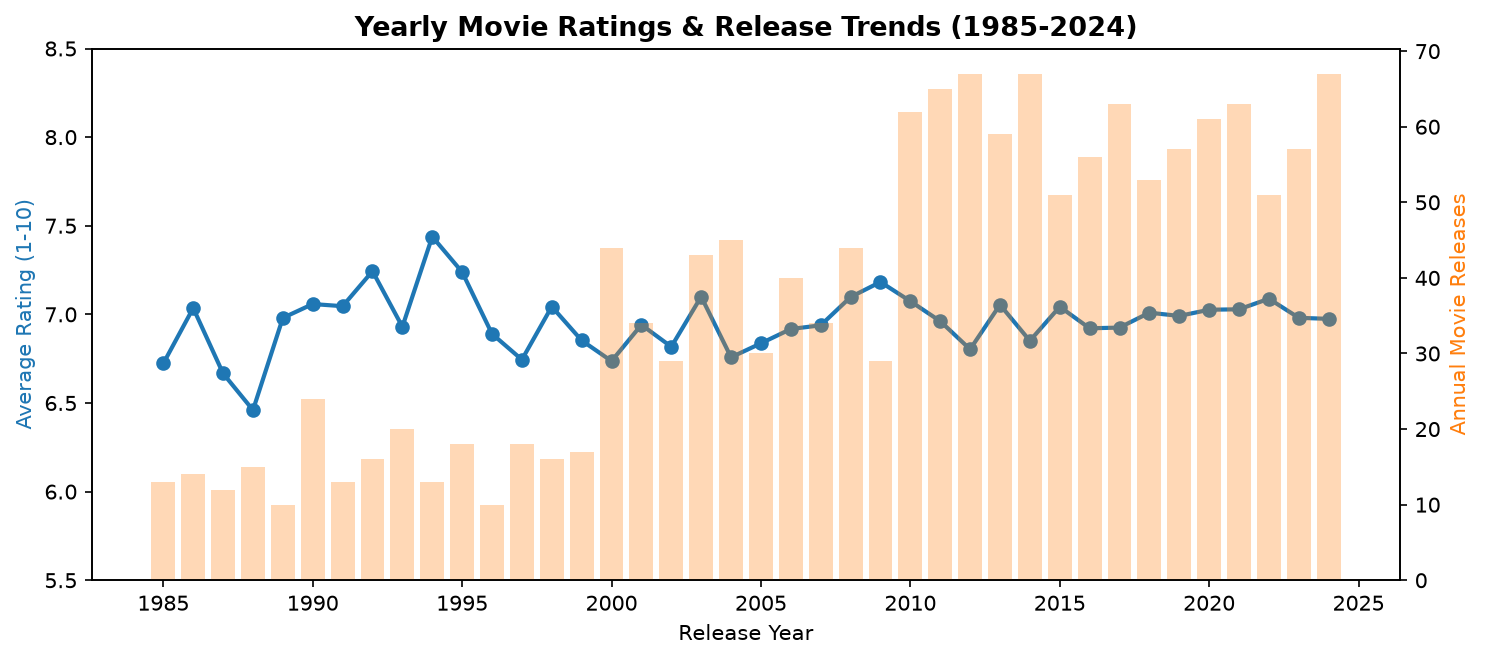

In [6]:
# 1. Plot yearly ratings and release trends
yearlyTrends = movies.groupby('Release_Year').agg(
    avg_rating=('Rating', 'mean'),
    movie_count=('Movie_ID', 'count')
).reset_index()

fig, ax1 = plt.subplots(figsize=(10, 4.5))
ax1.plot(yearlyTrends['Release_Year'], yearlyTrends['avg_rating'], marker='o', color='#1f77b4', linewidth=2, label='Avg Rating')
ax1.set_title('Yearly Movie Ratings & Release Trends (1985-2024)', fontsize=13, fontweight='bold')
ax1.set_xlabel('Release Year')
ax1.set_ylabel('Average Rating (1-10)', color='#1f77b4')
ax1.set_ylim(5.5, 8.5)

ax2 = ax1.twinx()
ax2.bar(yearlyTrends['Release_Year'], yearlyTrends['movie_count'], color='#ff7f0e', alpha=0.3, width=0.8)
ax2.set_ylabel('Annual Movie Releases', color='#ff7f0e')
ax2.grid(False)
plt.tight_layout()
plt.show()

## Genre Popularity vs. Critical Acclaim

We contrast commercially successful, high-grossing genres (e.g., Action, Sci-Fi) against critically acclaimed, highly-rated genres (e.g., Drama, Documentary).

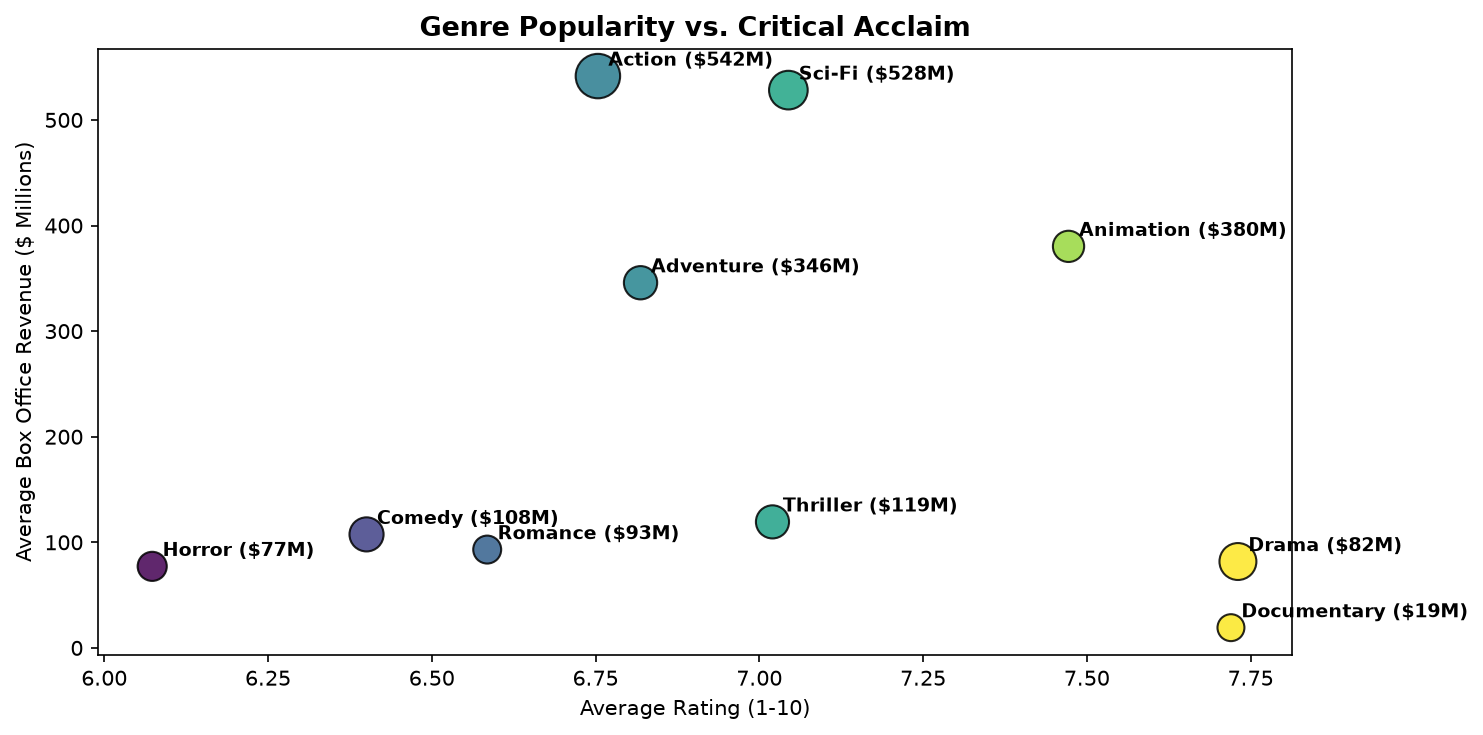

In [7]:
# 2. Scatter plot: Genre Popularity vs Critical Acclaim
genreSummary = movies.groupby('Genre').agg(
    avg_rating=('Rating', 'mean'),
    avg_box_office=('Box_Office_Million', 'mean'),
    total_votes=('Votes', 'sum')
).reset_index()

plt.figure(figsize=(10, 5))
plt.scatter(
    genreSummary['avg_rating'], 
    genreSummary['avg_box_office'],
    s=genreSummary['total_votes'] / 600000 + 150,
    c=genreSummary['avg_rating'],
    cmap='viridis', alpha=0.85, edgecolors='black'
)

for _, row in genreSummary.iterrows():
    plt.annotate(f"{row['Genre']} (${row['avg_box_office']:.0f}M)",
                 xy=(row['avg_rating'], row['avg_box_office']),
                 xytext=(5, 5), textcoords='offset points', fontsize=9, fontweight='bold')

plt.title('Genre Popularity vs. Critical Acclaim', fontsize=13, fontweight='bold')
plt.xlabel('Average Rating (1-10)')
plt.ylabel('Average Box Office Revenue ($ Millions)')
plt.tight_layout()
plt.show()

## Impact of Movie Runtime on Ratings

We evaluate how film length impacts viewer rating scores by segmenting movies into 5 runtime duration brackets.

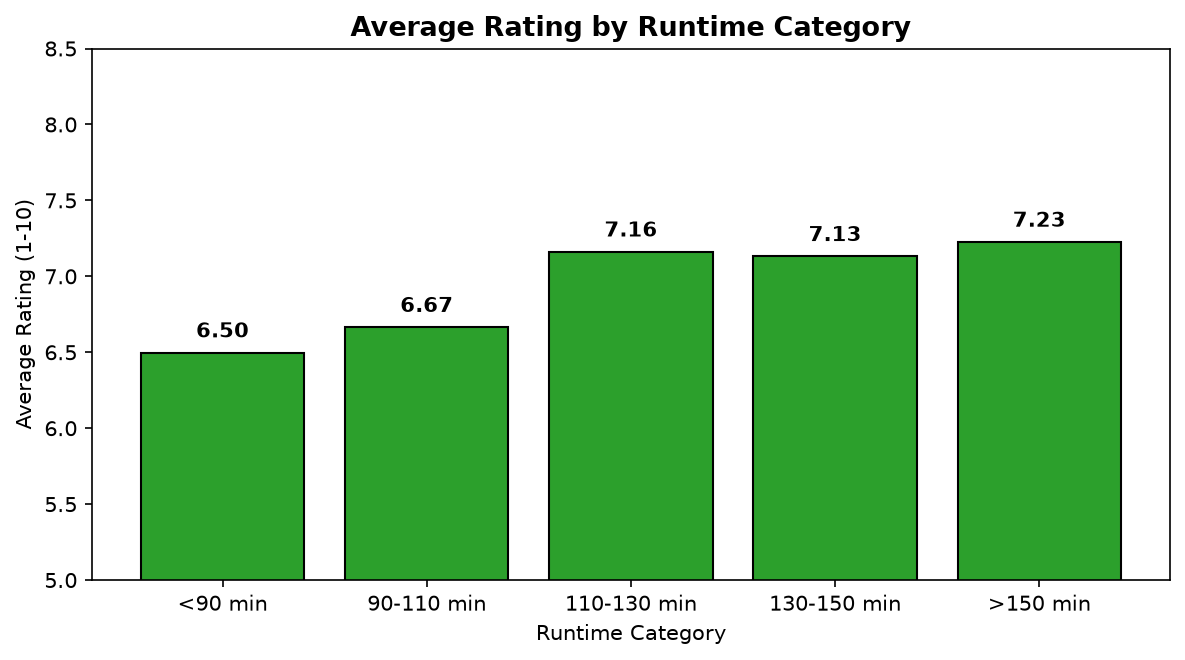

In [8]:
# 3. Impact of runtime categories on ratings
movies['Runtime_Bucket'] = pd.cut(
    movies['Runtime_Minutes'], 
    bins=[0, 90, 110, 130, 150, 300], 
    labels=['<90 min', '90-110 min', '110-130 min', '130-150 min', '>150 min']
)

runtimePerformance = movies.groupby('Runtime_Bucket', observed=False).agg(
    avg_rating=('Rating', 'mean'),
    movie_count=('Movie_ID', 'count')
).reset_index()

plt.figure(figsize=(8, 4.5))
bars = plt.bar(runtimePerformance['Runtime_Bucket'], runtimePerformance['avg_rating'], color='#2ca02c', edgecolor='black')
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 0.1, f'{yval:.2f}', ha='center', fontweight='bold')

plt.title('Average Rating by Runtime Category', fontsize=13, fontweight='bold')
plt.xlabel('Runtime Category')
plt.ylabel('Average Rating (1-10)')
plt.ylim(5.0, 8.5)
plt.tight_layout()
plt.show()

## Total Box Office Revenue by Genre

We calculate total gross box office earnings generated across all genres to measure commercial dominance.

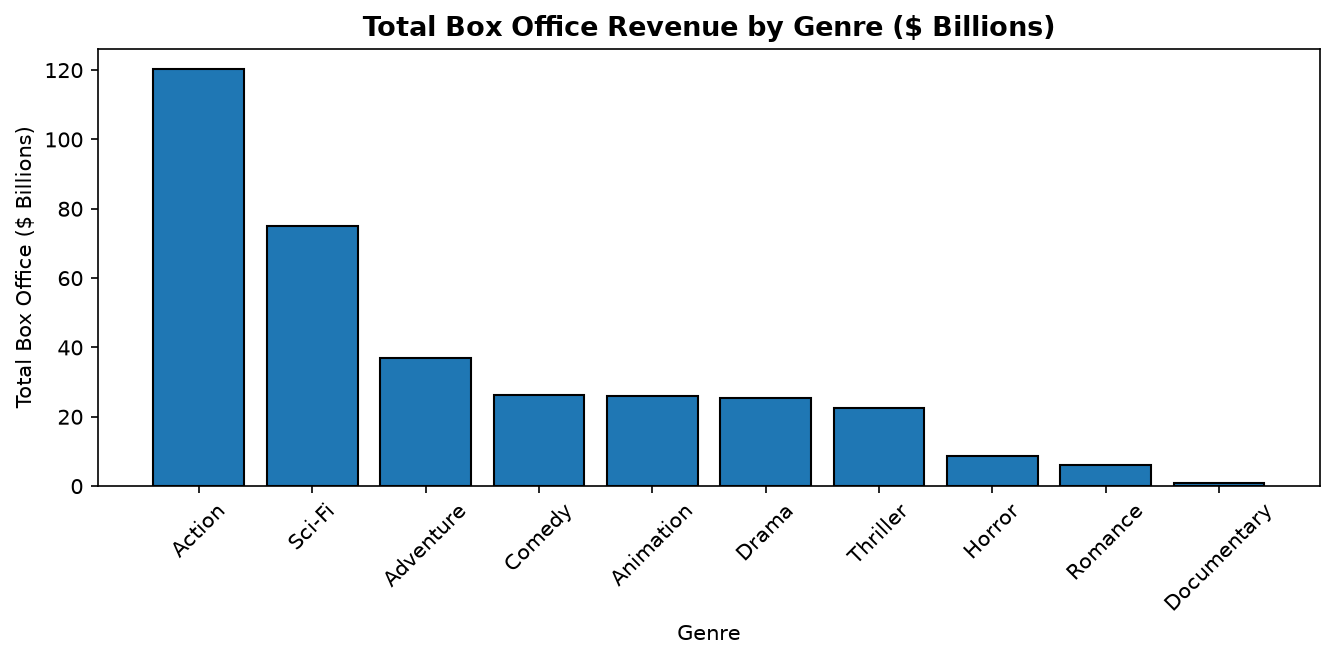

In [9]:
# 4. Bar chart of total box office revenue by genre
genreRevenue = movies.groupby('Genre')['Box_Office_Million'].sum().sort_values(ascending=False).reset_index()

plt.figure(figsize=(9, 4.5))
plt.bar(genreRevenue['Genre'], genreRevenue['Box_Office_Million'] / 1000.0, color='#1f77b4', edgecolor='black')
plt.title('Total Box Office Revenue by Genre ($ Billions)', fontsize=13, fontweight='bold')
plt.xlabel('Genre')
plt.ylabel('Total Box Office ($ Billions)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Summary

### Key Findings:
- **Genre Popularity vs. Critical Acclaim:** **Action** ($120.2B total, $541.5M avg) and **Sci-Fi** ($75.0B total, $528.2M avg) lead commercial box office and audience votes. In contrast, **Drama** (7.73 / 10), **Documentary** (7.72 / 10), and **Animation** (7.47 / 10) command the highest critical ratings.
- **Runtime Impact:** Movies running between **110 and 130 minutes** hit the critical rating "sweet spot" (7.16 / 10), while films under 90 minutes have noticeably lower ratings (6.50 / 10).
- **Top Commercial Genres:** Action, Sci-Fi, and Adventure together generate over 66% of all tracked box office revenue.
- **Catalog Recommendations:** Streaming platforms should pair high-turnover Action/Sci-Fi films with high-acclaim Dramas and Documentaries to maximize subscriber acquisition and long-term retention.